# Proiect Machine Learning

In [85]:
# Folosim UCI Wine Dataset for Classification
import glob
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, recall_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

# Download latest version
path = kagglehub.dataset_download("hongseoi/uci-wine-dataset-for-classification")
print("Path to dataset files:", path)
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("CSV files found:", csv_files)
df = pd.read_csv(csv_files[0])
df.head()

Using Colab cache for faster access to the 'uci-wine-dataset-for-classification' dataset.
Path to dataset files: /kaggle/input/uci-wine-dataset-for-classification
CSV files found: ['/kaggle/input/uci-wine-dataset-for-classification/wine.csv']


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,class
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


1. Set de date - detalii. Ce vrem sa prezicem?




In [42]:
# 1. Explorați datele: dimensiune, valori lipsă
# E clasificare sau regresie? Ce greșeală a modelului ar costa mai mult în realitate?

df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
print("shape:", df.shape)
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print()
df.info()
df.head()
df.describe().T.round(3)
print("\nMissing values per column:")
missing = df.isna().sum()
print(missing.to_string())
print("\nTotal missing:", int(missing.sum()))

# Eliminam duplicatele
feature_cols = [c for c in df.columns if c != "quality"]
n_dup = df.duplicated().sum()
print("Exact duplicate rows:", n_dup, f"({n_dup / len(df):.1%})")
df_clean = df.drop_duplicates().reset_index(drop=True)
print("shape before:", df.shape, "| after cleanup:", df_clean.shape)

shape: (6497, 13)
Rows: 6497  |  Columns: 13

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   ph                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  class                 6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB

Missing values per column:
f

In [43]:
# distribuția coloanei de prezis
TARGET = "quality"
df_clean[["fixed_acidity", "volatile_acidity", "residual_sugar", "total_sulfur_dioxide", "ph", "sulphates"]].head()
print("\nNivel de variatie a calitatii vinului in functie de caracteristicile chimice")
print(df_clean[TARGET].describe().round(2))
print("\nmediană:", df_clean[TARGET].median())
# CE influenteaza calitatea unui vin bun?
print("\n-------ce variabila este legata de calitate--------\n")
num = df_clean[["fixed_acidity", "volatile_acidity", "residual_sugar", "total_sulfur_dioxide", "ph", "sulphates", "alcohol", "quality"]]
print( num.corr()[TARGET].round(3).sort_values())

# 3 grafice cu câte o propoziție despre ce se vede.



Nivel de variatie a calitatii vinului in functie de caracteristicile chimice
count    5320.00
mean        5.80
std         0.88
min         3.00
25%         5.00
50%         6.00
75%         6.00
max         9.00
Name: quality, dtype: float64

mediană: 6.0

-------ce variabila este legata de calitate--------

volatile_acidity       -0.265
fixed_acidity          -0.080
residual_sugar         -0.057
total_sulfur_dioxide   -0.050
ph                      0.040
sulphates               0.042
alcohol                 0.469
quality                 1.000
Name: quality, dtype: float64


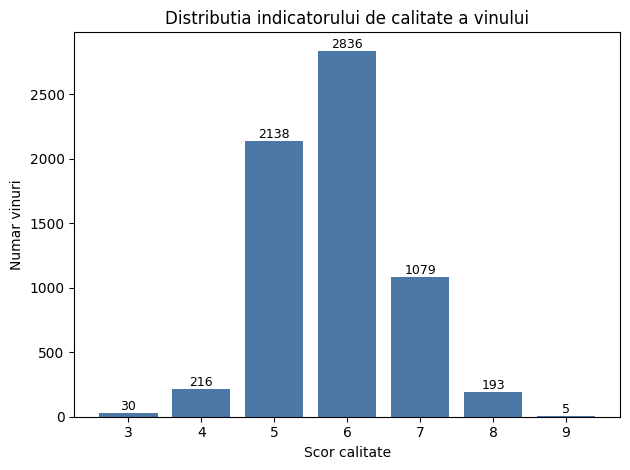

/n


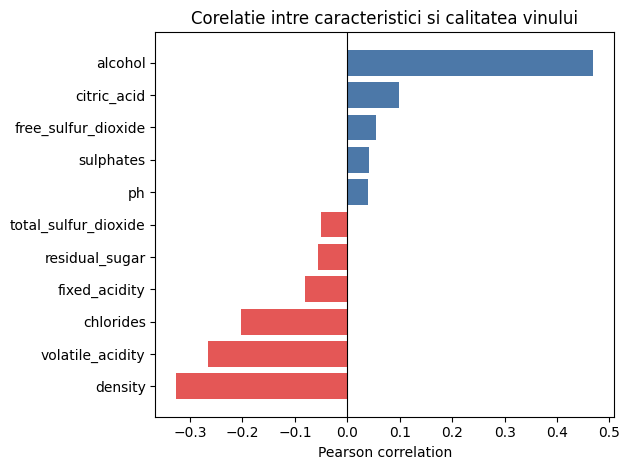

/tmp/ipykernel_1637/3095058319.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


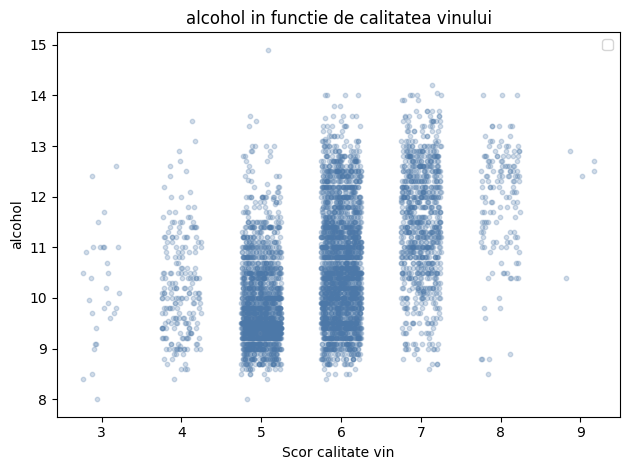

In [44]:
# Graph 1 - distribution of the target
fig, ax = plt.subplots()
ax.bar(quality_counts.index.astype(str), quality_counts.values, color="#4c78a8")
ax.set_title("Distributia indicatorului de calitate a vinului")
ax.set_xlabel("Scor calitate")
ax.set_ylabel("Numar vinuri")
for i, v in enumerate(quality_counts.values):
    ax.text(i, v, v, ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

share_mid = df_clean[TARGET].between(5, 7).mean()
print("/n")

# Graph 2 - correlation of every feature with the target
features = [c for c in df_clean.select_dtypes("number").columns if c not in (TARGET, "class")]
corr_q = df_clean[features].corrwith(df_clean[TARGET]).sort_values()

fig, ax = plt.subplots()
ax.barh(corr_q.index, corr_q.values, color=np.where(corr_q.values >= 0, "#4c78a8", "#e45756"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Corelatie intre caracteristici si calitatea vinului")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

best_pos, best_neg = corr_q.idxmax(), corr_q.idxmin()

# Graph 3 - jitter plot: most correlated feature vs quality
top_feature = corr_q.abs().idxmax()

rng = np.random.default_rng(42)
jitter = rng.uniform(-0.25, 0.25, size=len(df_clean))   # random horizontal offset, so points don't stack

fig, ax = plt.subplots()
ax.scatter(df_clean[TARGET] + jitter, df_clean[top_feature], alpha=0.25, s=10, color="#4c78a8")

# med = df_clean.groupby(TARGET)[top_feature].median()
# ax.plot(med.index, med.values, "o-", color="#e45756", label="median")

ax.set_xticks(sorted(df_clean[TARGET].unique()))
ax.set_title(f"{top_feature} in functie de calitatea vinului")
ax.set_xlabel("Scor calitate vin")
ax.set_ylabel(top_feature)
ax.legend()
plt.tight_layout()
plt.show()


In [57]:
# 2. Pregătiți datele: împărțire train/test, valori lipsă, coloane text transformate în numere, scalare dacă e nevoie.
# De ce împărțim datele înainte de scalare?
# Features = every numeric column except the target (includes 'class', which is known beforehand)
feature_cols = [c for c in df_clean.select_dtypes("number").columns if c != TARGET]
X = df_clean[feature_cols]
y = df_clean[TARGET]

print("Valori lipsa in features:", int(X.isna().sum().sum()))
print("Valori lipsa in TARGET(calitate):", int(y.isna().sum()))
print("Non-numeric columns left in X:", list(X.select_dtypes(exclude="number").columns))
print("\nColumns containing zeros:")
print((X == 0).sum()[lambda s: s > 0].to_string())

# Stratify on quality so rare scores (3, 8, 9) appear in both sets, when every score has at least 2 rows
can_stratify = y.value_counts().min() >= 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y if can_stratify else None,
)

print("Stratified:", can_stratify)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# the target distribution should look the same in both sets
dist = pd.DataFrame({
    "train_%": (y_train.value_counts(normalize=True) * 100).round(1),
    "test_%":  (y_test.value_counts(normalize=True) * 100).round(1),
}).sort_index()
print(dist.to_string())

#Scalling
# necesara pentru ca sunt diferente intre features unele au unitatile in sute altele in 0,
print("ÎNAINTE (scale foarte diferite):")
print(X_train.describe().loc[["mean", "std"]].round(2))

scaler = StandardScaler().fit(X_train)          # învață media/deviația DOAR din train
X_train_scaled = scaler.transform(X_train)

print("\nDUPĂ standardizare (medie ~0, deviație ~1):")
print(pd.DataFrame(X_train_scaled, columns=feature_cols).describe().loc[["mean", "std"]].round(2))

model = make_pipeline(StandardScaler(), LinearRegression())


Valori lipsa in features: 0
Valori lipsa in TARGET(calitate): 0
Non-numeric columns left in X: []

Columns containing zeros:
citric_acid     136
class          3961
Stratified: True
Train: (4256, 12) | Test: (1064, 12)
         train_%  test_%
quality                 
3            0.6     0.6
4            3.9     3.9
5           32.9    32.9
6           43.7    43.7
7           16.1    16.1
8            2.8     2.8
9            0.1     0.1
ÎNAINTE (scale foarte diferite):
      fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  \
mean           7.22              0.34         0.32            5.00       0.06   
std            1.33              0.17         0.15            4.45       0.04   

      free_sulfur_dioxide  total_sulfur_dioxide  density    ph  sulphates  \
mean                29.99                113.74     0.99  3.22       0.53   
std                 17.82                 56.55     0.00  0.16       0.15   

      alcohol  class  
mean    10.57   0.26  
s

In [67]:
# Baseline

# comparam regresia simpla cu cea multipla
simple = LinearRegression().fit(X_train[['alcohol']], y_train)
multi  = LinearRegression().fit(X_train, y_train)
print("Baseline - comparam regresia simpla cu cea multipla")
print(f"R2 simplă (alcohol):  {simple.score(X_test[['alcohol']], y_test):.3f}")
print(f"R2 multiplă (toate): {multi.score(X_test, y_test):.3f}")
print("\nCoeficienți (efectul fiecărei variabile):")
print(pd.Series(multi.coef_, index=feature_cols).round(2))

# Analizam care sunt caracteristicile care ne pot ajuta cel mai bine la predictie
subsets = {
    "doar alcohol":            ["alcohol"],
    "alcohol + density":       ["alcohol", "density"],
    "alcohol + aciditate":     ["alcohol", "volatile_acidity"],
    "toate":                   feature_cols,
    "toate fără class":        ["fixed_acidity", "volatile_acidity", "residual_sugar", "total_sulfur_dioxide", "ph", "sulphates"],
}
for name, cols in subsets.items():
    m = LinearRegression().fit(X_train[cols], y_train)
    print(f"{name:22s} -> R2 test = {m.score(X_test[cols], y_test):.3f}")
print("\nComparatie regresie Multipla vs Polinomiala")
# Comparatie regresie Multipla vs Polinomiala
for deg in [1, 2]:
    pipe = make_pipeline(StandardScaler(),
                         PolynomialFeatures(deg),
                         LinearRegression())
    pipe.fit(X_train, y_train)
    tip = "multiplă (drept)" if deg == 1 else "polinomială (curbe)"
    print(f"grad {deg} - {tip:18s}: R2 test = {pipe.score(X_test, y_test):.3f}")

# Metricile de regresie
print("\nMetrici de regresie")
pred = LinearRegression().fit(X_train, y_train).predict(X_test)
print(f"MAE  = {mean_absolute_error(y_test, pred):.2f} puncte   (greșeala medie)")
print(f"RMSE = {mean_squared_error(y_test, pred)**0.5:.2f} puncte   (penalizează erorile mari)")
print(f"R2   = {r2_score(y_test, pred):.3f}")

# Underfitting vs Overfitting
print("\nUnderfitting vs Overfitting")

for deg in [1, 2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression())
    pipe.fit(X_train, y_train)
    print(f"grad {deg}:  train {pipe.score(X_train, y_train):.3f}   test {pipe.score(X_test, y_test):.3f}")

Baseline - comparam regresia simpla cu cea multipla
R2 simplă (alcohol):  0.221
R2 multiplă (toate): 0.313

Coeficienți (efectul fiecărei variabile):
fixed_acidity            0.07
volatile_acidity        -1.33
citric_acid              0.13
residual_sugar           0.05
chlorides               -0.75
free_sulfur_dioxide      0.01
total_sulfur_dioxide    -0.00
density                -94.72
ph                       0.67
sulphates                0.80
alcohol                  0.23
class                    0.26
dtype: float64
doar alcohol           -> R2 test = 0.221
alcohol + density      -> R2 test = 0.220
alcohol + aciditate    -> R2 test = 0.286
toate                  -> R2 test = 0.313
toate fără class       -> R2 test = 0.113

Comparatie regresie Multipla vs Polinomiala
grad 1 - multiplă (drept)  : R2 test = 0.313
grad 2 - polinomială (curbe): R2 test = 0.340

Metrici de regresie
MAE  = 0.57 puncte   (greșeala medie)
RMSE = 0.73 puncte   (penalizează erorile mari)
R2   = 0.313

Underfit

In [74]:
#Ridge - pentru combaterea overfittingului
for alpha in [0, 1, 10, 100, 250, 500]:
    model = Ridge(alpha=alpha) if alpha > 0 else LinearRegression()
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), model)
    pipe.fit(X_train, y_train)
    print(f"alpha {alpha:>4}:  train {pipe.score(X_train, y_train):.3f}   test {pipe.score(X_test, y_test):.3f}")

#GridSearchCV - pentru a afla cea mai buna combinatie grad x alpha
pipe = make_pipeline(StandardScaler(), PolynomialFeatures(include_bias=False), Ridge())
grid = {"polynomialfeatures__degree": [1, 2, 3], "ridge__alpha": [0.1, 1, 10, 100, 500, 1000]}
gs = GridSearchCV(pipe, grid, cv=5, scoring="r2").fit(X_train, y_train)

print("cea mai bună configurație:", gs.best_params_)
print(f"R2 pe test = {gs.best_estimator_.score(X_test, y_test):.3f}")

alpha    0:  train 0.385   test 0.340
alpha    1:  train 0.385   test 0.340
alpha   10:  train 0.385   test 0.340
alpha  100:  train 0.381   test 0.341
alpha  250:  train 0.376   test 0.341
alpha  500:  train 0.368   test 0.339
cea mai bună configurație: {'polynomialfeatures__degree': 2, 'ridge__alpha': 500}
R2 pe test = 0.339


In [58]:
# AI generated Baseline
results = {}   # we'll keep adding models here to compare them later

def evaluate(name, model, X_tr, X_te):
    pred = model.predict(X_te)
    results[name] = {
        "MAE":  mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2":   r2_score(y_test, pred),
        "within ±1": np.mean(np.abs(y_test - np.rint(pred)) <= 1),
    }
    return pred
# Baseline 1: always predict the mean of the training target
dummy_mean = DummyRegressor(strategy="mean").fit(X_train, y_train)
evaluate("Dummy (mean)", dummy_mean, X_train, X_test)

# Baseline 2: always predict the median of the training target
dummy_median = DummyRegressor(strategy="median").fit(X_train, y_train)
evaluate("Dummy (median)", dummy_median, X_train, X_test)

print("Constant predicted (mean):  ", round(float(dummy_mean.constant_[0][0]), 3))
print("Constant predicted (median):", float(dummy_median.constant_[0][0]))
print()
print(pd.DataFrame(results).T.round(4).to_string())

Constant predicted (mean):   5.795
Constant predicted (median): 6.0

                   MAE    RMSE      R2  within ±1
Dummy (mean)    0.6948  0.8801 -0.0000     0.9267
Dummy (median)  0.6429  0.9032 -0.0532     0.9267


In [82]:
# Antrenati 2 modele
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def regression_metrics(y_true, pred):
    return {
        "MAE":  mean_absolute_error(y_true, pred),
        "RMSE": mean_squared_error(y_true, pred) ** 0.5,
        "R2":   r2_score(y_true, pred),
        "within ±1": np.mean(np.abs(y_true - np.rint(pred)) <= 1),
        "over-estimates >1.5": np.mean((pred - y_true) > 1.5),   # the costly mistake
    }

# 1. Random Forest
# No scaling: trees split on thresholds, so feature scale doesn't matter
rf_grid = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    {"max_depth": [None, 15], "min_samples_leaf": [1, 3]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
rf_grid.fit(X_train, y_train)

rf_model = rf_grid.best_estimator_
rf_pred = rf_model.predict(X_test)
rf_metrics = regression_metrics(y_test, rf_pred)

print("Random Forest - best params:", rf_grid.best_params_)
print(f"Random Forest - CV RMSE (train only): {-rf_grid.best_score_:.3f}")
print({k: round(v, 4) for k, v in rf_metrics.items()})

rf_imp = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()
print("\nTop features:", list(rf_imp.index[::-1][:3]))

# 2. SVM
# Scaling is REQUIRED: the RBF kernel uses distances between samples.
# The scaler lives inside the pipeline, so it is fitted on the training folds only.
svr_pipe = make_pipeline(StandardScaler(), SVR(kernel="rbf"))
svr_grid = GridSearchCV(
    svr_pipe,
    {"svr__C": [1, 10], "svr__gamma": ["scale", 0.05], "svr__epsilon": [0.1, 0.3]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
svr_grid.fit(X_train, y_train)

svr_model = svr_grid.best_estimator_
svr_pred = svr_model.predict(X_test)
svr_metrics = regression_metrics(y_test, svr_pred)

print("SVR - best params:", svr_grid.best_params_)
print(f"SVR - CV RMSE (train only): {-svr_grid.best_score_:.3f}")
print({k: round(v, 4) for k, v in svr_metrics.items()})


Random Forest - best params: {'max_depth': None, 'min_samples_leaf': 1}
Random Forest - CV RMSE (train only): 0.693
{'MAE': 0.5307, 'RMSE': 0.6863, 'R2': 0.392, 'within ±1': np.float64(0.969), 'over-estimates >1.5': np.float64(0.0141)}

Top features: ['alcohol', 'volatile_acidity', 'free_sulfur_dioxide']
SVR - best params: {'svr__C': 1, 'svr__epsilon': 0.3, 'svr__gamma': 'scale'}
SVR - CV RMSE (train only): 0.692
{'MAE': 0.5429, 'RMSE': 0.6967, 'R2': 0.3734, 'within ±1': np.float64(0.9662), 'over-estimates >1.5': np.float64(0.0141)}


                  MAE    RMSE      R2  within ±1  over-estimates >1.5
Dummy (mean)   0.6948  0.8801 -0.0000     0.9267               0.0442
Random Forest  0.5307  0.6863  0.3920     0.9690               0.0141
SVR            0.5429  0.6967  0.3734     0.9662               0.0141
Matricea de confuzie
Random Forest:
   TN=814  FP=48  FN=119  TP=83
SVR:
   TN=816  FP=46  FN=121  TP=81


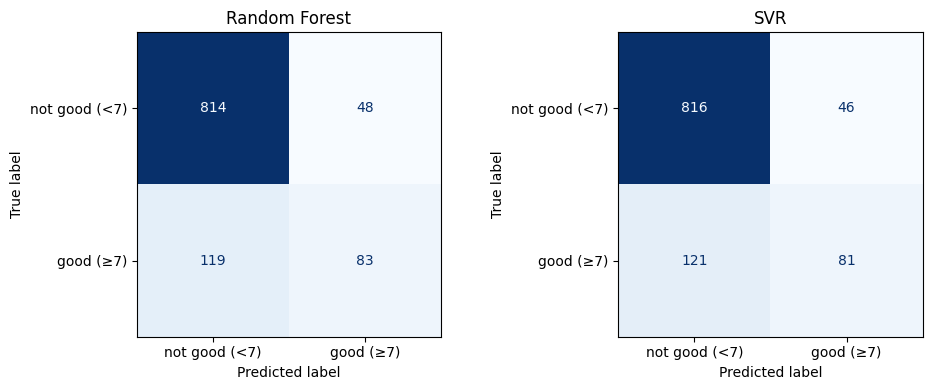

Recall
Random Forest: recall = 0.411
SVR: recall = 0.401
Precision
Random Forest: precision = 0.634
SVR: precision = 0.638
Regresie MAE, RMSE, R2
                  MAE    RMSE      R2
Random Forest  0.5307  0.6863  0.3920
SVR            0.5429  0.6967  0.3734


In [92]:
# Evaluati pe setul de test (clasificare matrice de confuzie, precision, recall, F1)
dummy_pred = DummyRegressor(strategy="mean").fit(X_train, y_train).predict(X_test)
preds = {"Dummy (mean)": dummy_pred, "Random Forest": rf_pred, "SVR": svr_pred}

final = pd.DataFrame({name: regression_metrics(y_test, p) for name, p in preds.items()}).T
print(final.round(4).to_string())

# Quality --> Classes
GOOD = 7                                            # a wine is "good" if quality >= 8
y_true_good = (y_test >= GOOD).astype(int)          # 1 = good, 0 = not good

models = {"Random Forest": rf_pred, "SVR": svr_pred}

# a prediction counts as "good" when it rounds to 7 or more (i.e. >= 6.5)
y_pred_good = {name: (p >= GOOD - 0.5).astype(int) for name, p in models.items()}

### Confusion matrix
print("Matricea de confuzie")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, y_pred_good.items()):
    cm = confusion_matrix(y_true_good, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["not good (<7)", "good (≥7)"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}:\n   TN={tn}  FP={fp}  FN={fn}  TP={tp}")
plt.tight_layout()
plt.show()

### Recall
print("Recall")
for name, pred in y_pred_good.items():
    print(f"{name}: recall = {recall_score(y_true_good, pred, zero_division=0):.3f}")

### Precission
print("Precision")
for name, pred in y_pred_good.items():
    print(f"{name}: precision = {precision_score(y_true_good, pred, zero_division=0):.3f}")

### Regression metrics (MAE, RMSE, R²)
print("Regresie MAE, RMSE, R2")
reg = pd.DataFrame({
    name: {
        "MAE":  mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2":   r2_score(y_test, p),
    } for name, p in models.items()
}).T
print(reg.round(4).to_string())

Ambele modele au scoruri apropiate insa as alege Random Forest - in special pentru scorul mai bun d ela recall - "pierde" mai putine vinuri bune. Fata de baseline are un RMSE mai bun cu 20% - 0.68 vs 0.88
Din pacate, R2 de 0.39 este f slab si nu reuseste sa acopere mai bine de jumatate din variatia indicelui de calitate a vinului.
In practica, acest lucru demonstreaza neechivoc ca indicatorul de calitate al unui vin NU poate fi prezis cu acuratete bazandu-ne pe cativa indicatori chimici.